## Question 1: Customer Satisfaction Analysis

The data contains one missing satisfaction rating and a repeated CustomerID of 5. I would remove the duplicate customer record, fill the missing rating using the median of the remaining ratings, and then summarize the results. The median is a simple choice here because it is less affected by extreme scores.

Before cleaning: (10, 2)
After cleaning: (9, 2)
       CustomerID  Satisfaction
count    9.000000      9.000000
mean     5.000000      7.000000
std      2.738613      1.870829
min      1.000000      4.000000
25%      3.000000      6.000000
50%      5.000000      7.000000
75%      7.000000      8.000000
max      9.000000     10.000000
Average satisfaction: 7.0


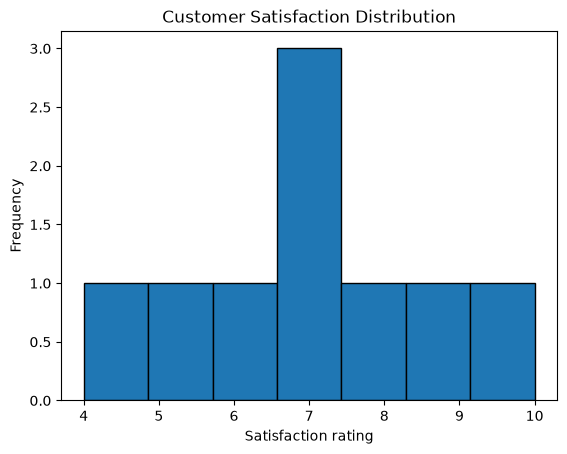

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    'CustomerID': [1, 2, 3, 4, 5, 5, 6, 7, 8, 9],
    'Satisfaction': [8, 7, np.nan, 9, 6, 6, 10, 4, 5, 7]
})
print('Before cleaning:', df.shape)
df = df.drop_duplicates(subset='CustomerID').copy()
df['Satisfaction'] = df['Satisfaction'].fillna(df['Satisfaction'].median())
print('After cleaning:', df.shape)
print(df.describe())
print('Average satisfaction:', round(df['Satisfaction'].mean(), 2))
df['Satisfaction'].plot(kind='hist', bins=7, edgecolor='black')
plt.xlabel('Satisfaction rating')
plt.title('Customer Satisfaction Distribution')
plt.show()


## Question 2: Product Sales Performance

  Month  Sales   Growth %
0   Jan   1500        NaN
1   Feb   1700  13.333333
2   Mar   1600  -5.882353
3   Apr   1800  12.500000
4   May   2200  22.222222
5   Jun   2100  -4.545455
Total sales: 10900
Average monthly sales: 1816.67
Highest sales month: May
Lowest sales month: Jan


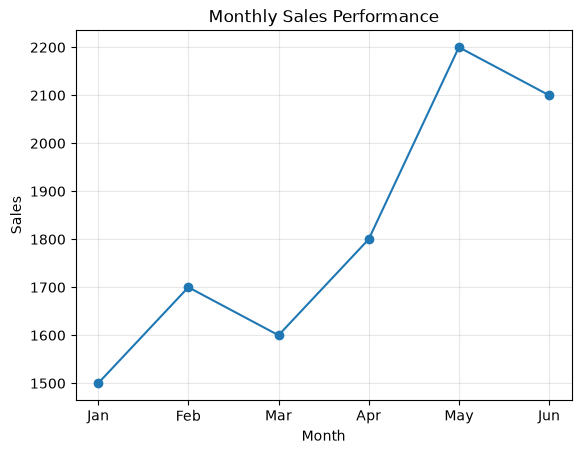

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    'Month': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'],
    'Sales': [1500, 1700, 1600, 1800, 2200, 2100]
})
df['Growth %'] = df['Sales'].pct_change() * 100
print(df)
print('Total sales:', df['Sales'].sum())
print('Average monthly sales:', round(df['Sales'].mean(), 2))
print('Highest sales month:', df.loc[df['Sales'].idxmax(), 'Month'])
print('Lowest sales month:', df.loc[df['Sales'].idxmin(), 'Month'])
plt.plot(df['Month'], df['Sales'], marker='o')
plt.title('Monthly Sales Performance')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid(alpha=0.3)
plt.show()


## Question 3: Medical Test Effectiveness

In [3]:
from scipy import stats

group_a = [110, 115, 108, 102, 107]
group_b = [120, 125, 130, 122, 128]
t_stat, p_value = stats.ttest_ind(group_a, group_b, equal_var=True)
print(f'T-Statistic: {t_stat:.2f}')
print(f'P-Value: {p_value:.4f}')
if p_value < 0.05:
    print('Reject Null Hypothesis: Significant difference between groups.')
else:
    print('Fail to reject Null Hypothesis: No significant difference detected.')


T-Statistic: -5.92
P-Value: 0.0004
Reject Null Hypothesis: Significant difference between groups.


## Question 4: Employee Performance Evaluation

Missing values after cleaning:
Department            0
Experience (Years)    0
Projects Completed    0
Performance Rating    0
dtype: int64
       Department  Experience (Years)  Projects Completed  Performance Rating
count          10           10.000000            10.00000             10.0000
unique          3                 NaN                 NaN                 NaN
top            HR                 NaN                 NaN                 NaN
freq            4                 NaN                 NaN                 NaN
mean          NaN            5.100000             8.50000              7.1000
std           NaN            2.988868             3.91578              2.1187
min           NaN            1.000000             2.00000              3.0000
25%           NaN            3.250000             6.00000              7.0000
50%           NaN            4.500000             9.50000              7.5000
75%           NaN            7.250000            10.75000              8.0000
ma

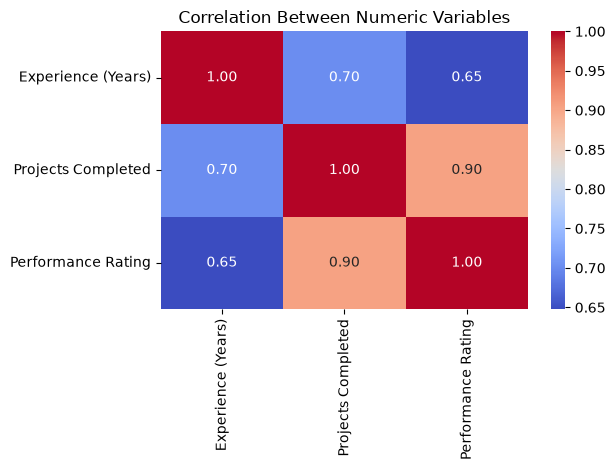

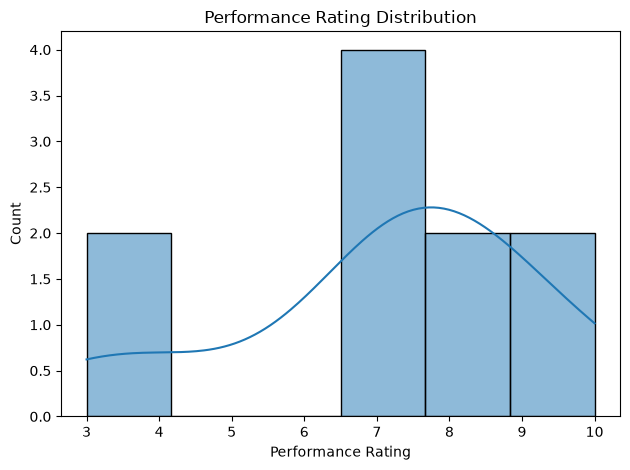

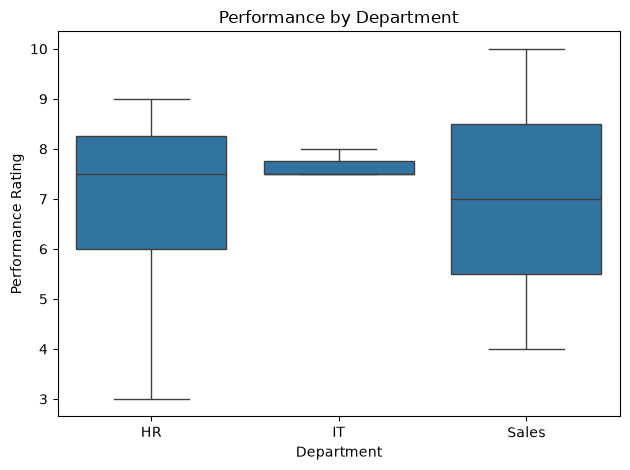

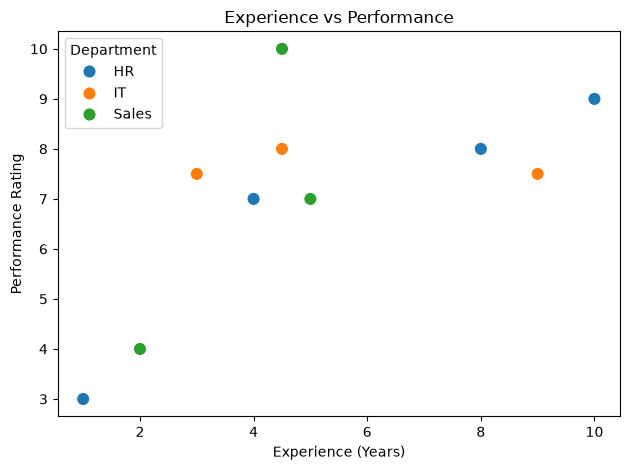

            Experience (Years)  Projects Completed  Performance Rating
Department                                                            
HR                        5.75                8.12                6.75
IT                        5.50                8.67                7.67
Sales                     3.83                8.83                7.00


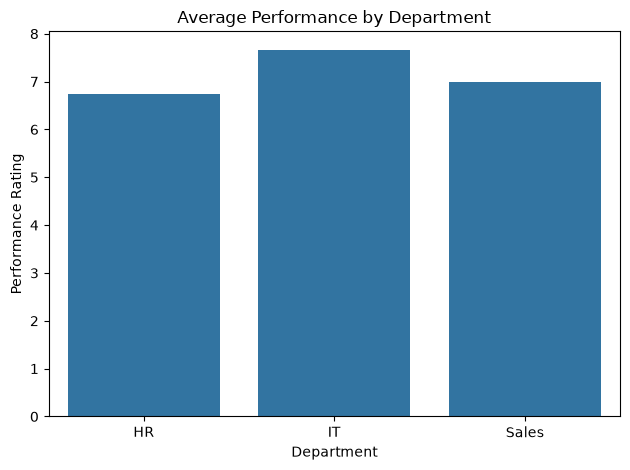

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    'Department': ['HR', 'IT', 'Sales', 'IT', 'HR', 'Sales', np.nan, 'HR', 'Sales', 'IT'],
    'Experience (Years)': [1., 3., 5., np.nan, 10., 2., 8., 4., np.nan, 9.],
    'Projects Completed': [2., 5., np.nan, 10., 12., 3., 9., np.nan, 14., 11.],
    'Performance Rating': [3., np.nan, 7., 8., 9., 4., 8., 7., 10., np.nan]
})
# 1. Data cleaning
# HR, IT and Sales tie in frequency; use 'HR' as an explicit rule.
df['Department'] = df['Department'].fillna('HR')
numeric_cols = df.select_dtypes(include='number').columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
print('Missing values after cleaning:')
print(df.isna().sum())
# 2. Descriptive statistics
print(df.describe(include='all'))
# 3. Correlation heatmap
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Numeric Variables')
plt.tight_layout(); plt.show()
# 4. Distribution histogram
sns.histplot(df['Performance Rating'], bins=6, kde=True)
plt.title('Performance Rating Distribution')
plt.tight_layout(); plt.show()
# 5. Department comparison boxplot
sns.boxplot(data=df, x='Department', y='Performance Rating')
plt.title('Performance by Department')
plt.tight_layout(); plt.show()
# 6. Experience vs performance scatter plot
sns.scatterplot(data=df, x='Experience (Years)', y='Performance Rating',
                hue='Department', s=90)
plt.title('Experience vs Performance')
plt.tight_layout(); plt.show()
# 7. Department-wise analysis
print(df.groupby('Department')[numeric_cols].mean().round(2))
sns.barplot(data=df, x='Department', y='Performance Rating', errorbar=None)
plt.title('Average Performance by Department')
plt.tight_layout(); plt.show()
